# Exploratory data analysis (EDA)

EDA means looking closely at the data before modelling. It tells us what the columns look
like, which problems we must handle, and what story the models should test.

- Summary statistics, skewness and outliers
- The Brent price history and the four shock periods
- How often stress happens, by year and by income group
- What predicts stress: current inflation, oil exposure, and correlations

In [1]:
import sys; sys.path.append('../src')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from config import *

# One chart style for the whole report
BLUE, ORANGE, RED = '#2a78d6', '#eb6834', '#e34948'
INK, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#e1e0d9', '#c3c2b7', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'font.family': 'sans-serif', 'font.size': 10, 'text.color': INK,
    'axes.edgecolor': AXIS, 'axes.labelcolor': MUTED, 'axes.titlelocation': 'left',
    'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': False, 'grid.color': GRID, 'grid.linewidth': 0.8,
})

panel = pd.read_csv('../data/processed/panel.csv')
labelled = panel.dropna(subset=['stress_next'])     # rows that have a target
train = labelled[labelled['year'] <= TRAIN_END_YEAR]  # 2010-2021 only
print(f"All rows: {len(panel)} | labelled: {len(labelled)} | training rows: {len(train)}")

All rows: 2400 | labelled: 2105 | training rows: 1701


## 1. Summary statistics and skewness

For each numeric column we report the range, mean, median and **skewness**. Skewness measures
how lopsided a distribution is: 0 is symmetric, and a large positive value means a few huge
values pull the mean far above the median. These statistics describe all years and are not
used to choose a model, so including the test years here does not affect the evaluation.

In [2]:
num = panel.drop(columns='year').select_dtypes('number')
summary = pd.DataFrame({
    'count': num.count(),
    'missing_pct': num.isna().mean() * 100,
    'mean': num.mean(),
    'median': num.median(),
    'std': num.std(),
    'min': num.min(),
    'max': num.max(),
    'skew': num.skew(),
}).round(2)
summary.to_csv(TABLES / 'summary_stats.csv')
summary

,count,missing_pct,mean,median,std,min,max,skew
gdp_usd,2366,1.42,5.658846e+11,6.436893e+10,2.202007e+12,4.756284e+07,3.076970e+13,8.42
gdp_per_capita_usd,2366,1.42,1.615939e+04,6.279190e+03,2.237675e+04,3.306200e+02,1.472522e+05,2.26
gdp_growth_pct,2370,1.25,3.130000e+00,3.320000e+00,5.500000e+00,-5.034000e+01,8.683000e+01,1.10
inflation_pct,2248,6.33,6.200000e+00,3.330000e+00,1.547000e+01,-6.600000e+00,3.590900e+02,12.13
trade_pct_gdp,2190,8.75,8.655000e+01,7.628000e+01,5.053000e+01,0.000000e+00,4.121800e+02,2.31
crude_oil_import_usd,1731,27.88,9.287917e+09,7.143182e+07,3.360051e+10,1.200000e-01,3.655120e+11,6.07
crude_oil_export_usd,1421,40.79,1.085190e+10,8.449324e+07,3.030427e+10,8.000000e-01,3.052370e+11,4.79
oil_consumption_twh,2294,4.42,3.475700e+02,6.564000e+01,1.085840e+03,2.300000e-01,1.030298e+04,6.87
exchange_rate_lcu_per_usd,2285,4.79,9.294900e+02,1.056000e+01,4.399720e+03,2.800000e-01,8.950000e+04,10.90
production_total_tbpd,2352,2.00,6.483600e+02,1.901000e+01,2.084210e+03,-1.550000e+00,2.360723e+04,5.77


**Takeaway:** the data has heavy right tails. Median GDP is about \$64bn but the mean is about
\$566bn, with skewness of 8.4. Inflation has a median of 3.3% and a maximum of 359%
(skewness 12.1). `fx_change_pct` is the most extreme column, with skewness of 45.3.

## 2. Would a log transform help?

A **log transform** compresses large values, so a country 100 times larger is no longer 100
times further along the scale. We use `log1p` (the log of 1 + x) because it also works at zero.
This cell only measures the effect. Phase 2 will test whether it improves the models.

In [3]:
LOG_CANDIDATES = ['gdp_usd', 'gdp_per_capita_usd', 'crude_oil_import_usd', 'crude_oil_export_usd',
                  'oil_consumption_twh', 'import_burden_pct_gdp', 'oil_intensity']
log_skew = pd.DataFrame({
    'skew_raw': panel[LOG_CANDIDATES].skew(),
    'skew_after_log1p': np.log1p(panel[LOG_CANDIDATES]).skew(),
}).round(2)
log_skew.to_csv(TABLES / 'skew_before_after_log.csv')
log_skew

,skew_raw,skew_after_log1p
gdp_usd,8.42,-0.26
gdp_per_capita_usd,2.26,0.07
crude_oil_import_usd,6.07,-0.34
crude_oil_export_usd,4.79,-0.52
oil_consumption_twh,6.87,0.28
import_burden_pct_gdp,5.11,1.39
oil_intensity,1.98,0.82


**Takeaway:** logs remove almost all of the skew from the USD columns (GDP goes from 8.4 to
-0.26, crude imports from 6.1 to -0.34). `import_burden_pct_gdp` improves but stays skewed
(5.1 to 1.4). This supports testing log features in Phase 2 (open issue 4).

## 3. Outliers and data-quality checks

An **outlier** is a value far from the rest. Some are real economic events and some are data
problems, so we look at them before deciding what to do. We do not delete anything here.

In [4]:
checks = {
    'inflation above 100%': panel['inflation_pct'] > 100,
    'exchange-rate change above 100%': panel['fx_change_pct'] > 100,
    'oil exports above 100% of GDP': panel['export_dependence_pct_gdp'] > 100,
    'negative oil production': panel['production_total_tbpd'] < 0,
    'trade equal to 0% of GDP': panel['trade_pct_gdp'] == 0,
}
rows = []
for name, mask in checks.items():
    hits = panel[mask]
    rows.append({'check': name, 'rows': len(hits), 'countries': hits['iso3'].nunique(),
                 'examples': ', '.join(sorted(hits['iso3'].unique())[:6])})
quality = pd.DataFrame(rows).set_index('check')
quality.to_csv(TABLES / 'data_quality_checks.csv')
display(quality)
panel.nlargest(5, 'fx_change_pct')[['iso3', 'year', 'fx_change_pct', 'inflation_pct']].round(1)

,rows,countries,examples
check,,,
inflation above 100%,10,4,"ARG, LBN, SDN, VEN"
exchange-rate change above 100%,12,8,"ARG, LBN, LBY, MMR, NGA, SDN"
oil exports above 100% of GDP,1,1,GUY
negative oil production,78,10,"BIH, CRI, DOM, JAM, KEN, LKA"
trade equal to 0% of GDP,2,1,VEN


,iso3,year,fx_change_pct,inflation_pct
1442,MMR,2012,11667.8,1.5
1261,LBN,2023,820.4,221.3
1963,SDN,2021,586.7,359.1
1262,LBN,2024,545.0,45.2
2113,SYR,2011,330.6,4.8


**Takeaway:** most extreme values look like real crises (Sudan, Venezuela, Lebanon and Argentina
for inflation), so removing them would remove the events we want to predict. Three items look
like data problems and need a decision in Phase 2:
- Myanmar's 11,668% exchange-rate change in 2012 is probably a change of exchange-rate regime
  rather than a true devaluation (to be checked);
- small negative oil-production values appear for a group of minor producers, and these are not
  physically meaningful;
- Venezuela's trade is recorded as 0% of GDP in 2010-11, which is a gap rather than a real value.

## 4. The Brent oil price and the four shock periods

Oil price is the event our project is about. We mark the 2014-16 crash, the 2020 COVID collapse,
the 2022 spike and the 2026 Iran-related shock, which is the one we want to score.

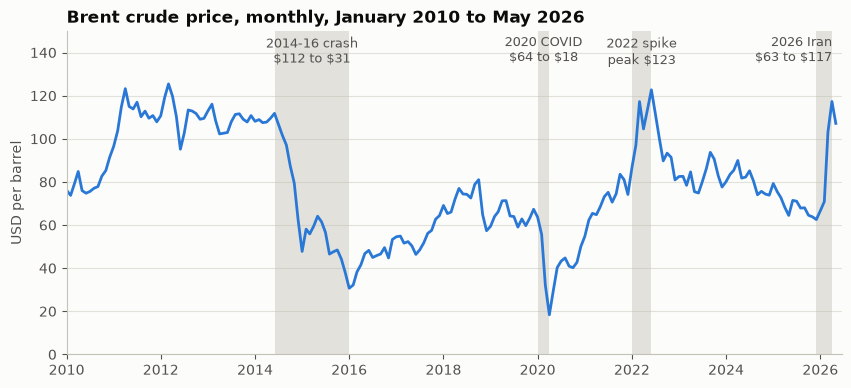

In [5]:
market = pd.read_csv(RAW / '03_global_market_monthly_master.csv', parse_dates=['period'])

SHOCKS = [('2014-06-01', '2016-01-01', '2014-16 crash\n\\$112 to \\$31', 'center'),
          ('2020-01-01', '2020-04-01', '2020 COVID\n\\$64 to \\$18', 'center'),
          ('2022-01-01', '2022-06-01', '2022 spike\npeak \\$123', 'center'),
          ('2025-12-01', '2026-04-01', '2026 Iran\n\\$63 to \\$117', 'right')]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(market['period'], market['brent_usd_bbl'], color=BLUE, linewidth=2)
for start, end, label, align in SHOCKS:
    start, end = pd.Timestamp(start), pd.Timestamp(end)
    ax.axvspan(start, end, color=AXIS, alpha=0.45, linewidth=0)
    x = end if align == 'right' else start + (end - start) / 2
    ax.text(x, 148, label, ha=align, va='top', fontsize=9, color=MUTED)
ax.set_ylim(0, 150)
ax.set_xlim(market['period'].min(), market['period'].max() + pd.Timedelta(days=45))
ax.set_ylabel('USD per barrel')
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.set_title('Brent crude price, monthly, January 2010 to May 2026')
fig.savefig(FIGURES / 'brent_price_shock_periods.png', dpi=150, bbox_inches='tight')
plt.show()

**Takeaway:** the 2026 move from \$63 in December 2025 to \$117 in April 2026 is an 88% rise in
four months. The sample also contains two large price falls and one earlier spike, so the
models see several kinds of oil episode, but only a few of them. Because Brent is the same for
every country in a given year, it only has 14 distinct values in the labelled data.

## 5. How often does stress happen, and when?

`stress_next` looks one year ahead, so the 2021 row is labelled with 2022 inflation. To make the
chart easy to read we plot each bar at the **year the stress actually occurred**. We colour the
bars by whether those rows are in the training set or the test set.

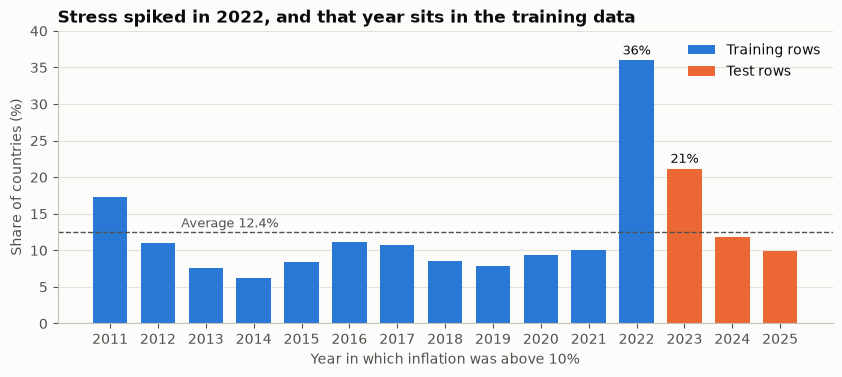

,rows,stress_cases,stress_rate,outcome_year,split,brent_yoy_pct
year,,,,,,
2010,145,25.0,0.172,2011,train,NaN
2011,145,16.0,0.110,2012,train,39.934
2012,144,11.0,0.076,2013,train,0.348
2013,144,9.0,0.062,2014,train,-2.700
2014,143,12.0,0.084,2015,train,-8.850
2015,143,16.0,0.112,2016,train,-47.130
2016,140,15.0,0.107,2017,train,-16.818
2017,140,12.0,0.086,2018,train,24.568
2018,140,11.0,0.079,2019,train,30.994


In [6]:
by_year = labelled.groupby('year')['stress_next'].agg(rows='size', stress_cases='sum', stress_rate='mean')
by_year['outcome_year'] = by_year.index + 1
by_year['split'] = np.where(by_year.index <= TRAIN_END_YEAR, 'train', 'test')
by_year['brent_yoy_pct'] = labelled.groupby('year')['brent_yoy_pct'].first()
by_year.round(3).to_csv(TABLES / 'stress_rate_by_year.csv')

overall = labelled['stress_next'].mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.8))
for split, colour, label in [('train', BLUE, 'Training rows'), ('test', ORANGE, 'Test rows')]:
    part = by_year[by_year['split'] == split]
    ax.bar(part['outcome_year'], part['stress_rate'] * 100, color=colour, width=0.72, label=label)
ax.axhline(overall, color=MUTED, linewidth=1, linestyle='--')
ax.text(2013.5, overall + 0.7, f'Average {overall:.1f}%', fontsize=9, color=MUTED, ha='center')
ax.set_ylim(0, 40)
for year in [2022, 2023]:
    value = by_year.loc[by_year['outcome_year'] == year, 'stress_rate'].iloc[0] * 100
    ax.text(year, value + 0.8, f'{value:.0f}%', ha='center', fontsize=9, color=INK)
ax.set_xticks(by_year['outcome_year'])
ax.set_ylabel('Share of countries (%)')
ax.set_xlabel('Year in which inflation was above 10%')
ax.yaxis.grid(True)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper right')
ax.set_title('Stress spiked in 2022, and that year sits in the training data')
fig.savefig(FIGURES / 'stress_rate_by_outcome_year.png', dpi=150, bbox_inches='tight')
plt.show()
by_year.round(3)

**Takeaway:** stress is rare in most years (6-12%) but reached 36% in 2022. This has three
consequences:
1. The target is **imbalanced** (stress is the minority class), so accuracy alone is misleading.
2. The test labels cover 2023-2025, so our main test never covers the start of the 2022 shock.
   Phase 2 adds a separate test: train on rows up to 2020 and test on the 2021 rows.
3. Oil is not the whole story. Brent rose 40% in 2011 and 25-31% in 2017-18 without a stress
   surge in the following year, and 2022 also reflects post-COVID supply problems.

## 6. Stress by income group

Are some kinds of economy more prone to stress? We use the World Bank income groups.

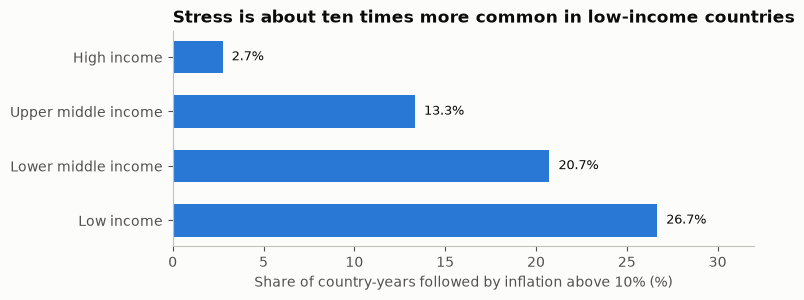

,rows,stress_cases,stress_rate
income_group,,,
High income,765,21.0,0.027
Upper middle income,630,84.0,0.133
Lower middle income,545,113.0,0.207
Low income,165,44.0,0.267


In [7]:
INCOME_ORDER = ['High income', 'Upper middle income', 'Lower middle income', 'Low income']
by_income = (labelled.groupby('income_group')['stress_next']
             .agg(rows='size', stress_cases='sum', stress_rate='mean').loc[INCOME_ORDER])
by_income.round(3).to_csv(TABLES / 'stress_rate_by_income_group.csv')

fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.barh(INCOME_ORDER, by_income['stress_rate'] * 100, color=BLUE, height=0.6)
for i, value in enumerate(by_income['stress_rate'] * 100):
    ax.text(value + 0.5, i, f'{value:.1f}%', va='center', fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_xlabel('Share of country-years followed by inflation above 10% (%)')
ax.set_xlim(0, 32)
ax.set_title('Stress is about ten times more common in low-income countries')
fig.savefig(FIGURES / 'stress_rate_by_income_group.png', dpi=150, bbox_inches='tight')
plt.show()
by_income.round(3)

**Takeaway:** the stress rate climbs from 2.7% in high-income countries to 26.7% in low-income
ones. Income is therefore a potential **confounder**: a third factor that can create a misleading
link between oil exposure and stress. Any oil result needs to be read with income in mind.

## 7. The persistence effect: does today's inflation predict next year's?

Open issue 1 says that current inflation may explain most of the predictive power. We group
rows by this year's inflation and see how often stress follows. We also count **new-onset**
stress: cases where inflation was at or below 10% this year and above 10% next year. Those are
the cases where an early warning is most valuable, because a simple rule cannot catch them.

In [8]:
bands = pd.cut(labelled['inflation_pct'], [-np.inf, 5, 10, np.inf], labels=['5% or less', '5-10%', 'above 10%'])
persistence = labelled.groupby(bands, observed=True)['stress_next'].agg(rows='size', stress_cases='sum', stress_rate='mean')
persistence.round(3).to_csv(TABLES / 'stress_rate_by_inflation_band.csv')
display(persistence.round(3))

# Share of stress cases that were new rather than a continuation, by split
onset = []
for name, part in [('train 2010-2021', labelled[labelled['year'] <= TRAIN_END_YEAR]),
                   ('test 2022-2024', labelled[labelled['year'] >= TEST_START_YEAR]),
                   ('2021 rows only (2022 shock)', labelled[labelled['year'] == 2021])]:
    stress = part[part['stress_next'] == 1]
    onset.append({'split': name, 'stress_cases': len(stress),
                  'new_onset': int((stress['inflation_pct'] <= 10).sum()),
                  'already_above_10': int((stress['inflation_pct'] > 10).sum()),
                  'inflation_missing': int(stress['inflation_pct'].isna().sum())})
onset = pd.DataFrame(onset).set_index('split')
onset['new_onset_share'] = (onset['new_onset'] / onset['stress_cases']).round(3)
onset.to_csv(TABLES / 'new_onset_by_split.csv')
onset

,rows,stress_cases,stress_rate
inflation_pct,,,
5% or less,1382,29.0,0.021
5-10%,460,57.0,0.124
above 10%,259,173.0,0.668


,stress_cases,new_onset,already_above_10,inflation_missing,new_onset_share
split,,,,,
train 2010-2021,204,80,121,3,0.392
test 2022-2024,58,6,52,0,0.103
2021 rows only (2022 shock),50,36,14,0,0.720


**Takeaway:** when inflation is already above 10%, stress follows 67% of the time, against 2% when
inflation is 5% or less. New-onset cases are 39% of stress cases in training but only 10% of the
test set (6 of 58). So the test years mostly reward predicting that high inflation continues.
The 2021 rows, which lead into the 2022 shock, are very different: 36 of their 50 stress cases are
new-onset. We should report results on new-onset cases as well as overall.

## 8. Does oil exposure relate to stress?

We use **training rows only** from here on, because these findings will shape feature choices,
and test data must not influence those. We sort rows into four equal groups (**quartiles**) by
oil exposure and compare stress rates. Because income is a likely confounder, we then repeat the
comparison inside each income group.

In [9]:
def rate_by_quartile(column):
    quartile = pd.qcut(train[column], 4, labels=['Q1 lowest', 'Q2', 'Q3', 'Q4 highest'])
    return train.groupby(quartile, observed=True)['stress_next'].mean()

quartiles = pd.DataFrame({'import_burden_pct_gdp': rate_by_quartile('import_burden_pct_gdp'),
                          'export_dependence_pct_gdp': rate_by_quartile('export_dependence_pct_gdp')}).round(3)
quartiles.to_csv(TABLES / 'stress_rate_by_oil_quartile.csv')
display(quartiles)

rows = []
for column in ['import_burden_pct_gdp', 'export_dependence_pct_gdp']:
    for group in INCOME_ORDER:
        part = train[(train['income_group'] == group) & train[column].notna()]
        median = part[column].median()
        rows.append({'feature': column, 'income_group': group, 'rows': len(part),
                     'stress_below_median': part.loc[part[column] <= median, 'stress_next'].mean(),
                     'stress_above_median': part.loc[part[column] > median, 'stress_next'].mean()})
within_income = pd.DataFrame(rows).round(3)
within_income.to_csv(TABLES / 'stress_rate_by_oil_within_income.csv', index=False)
within_income

,import_burden_pct_gdp,export_dependence_pct_gdp
Q1 lowest,0.126,0.062
Q2,0.102,0.081
Q3,0.090,0.107
Q4 highest,0.054,0.179


,feature,income_group,rows,stress_below_median,stress_above_median
0,import_burden_pct_gdp,High income,547,0.029,0.022
1,import_burden_pct_gdp,Upper middle income,372,0.054,0.102
2,import_burden_pct_gdp,Lower middle income,345,0.173,0.174
3,import_burden_pct_gdp,Low income,68,0.206,0.412
4,export_dependence_pct_gdp,High income,476,0.025,0.025
5,export_dependence_pct_gdp,Upper middle income,352,0.080,0.148
6,export_dependence_pct_gdp,Lower middle income,231,0.172,0.296
7,export_dependence_pct_gdp,Low income,31,0.125,0.600


**Takeaway:** this is the opposite of the simple story. Overall, stress *falls* as crude import
burden rises (12.6% in the lowest quartile, 5.4% in the highest), and *rises* with export
dependence (6.2% to 17.9%). Two reasons are likely:
- Big crude importers tend to be rich countries with refineries. Income explains part of this:
  inside low-income and upper-middle-income countries, the higher-burden half has about twice the
  stress rate (41% vs 21%, and 10% vs 5%). The low-income group is small, at 68 rows.
- The trade data covers crude oil only (HS code 2709). Countries that import refined fuel are
  exposed to oil prices but can look unexposed here.
Fuel exporters having higher stress may reflect sanctions, conflict and weak currencies.

## 9. Correlation heatmap

**Correlation** measures how closely two columns move together, from -1 to +1. We use **Spearman**
correlation, which compares rankings rather than raw values, so a single 359% inflation reading
cannot dominate the result. It uses training rows only.

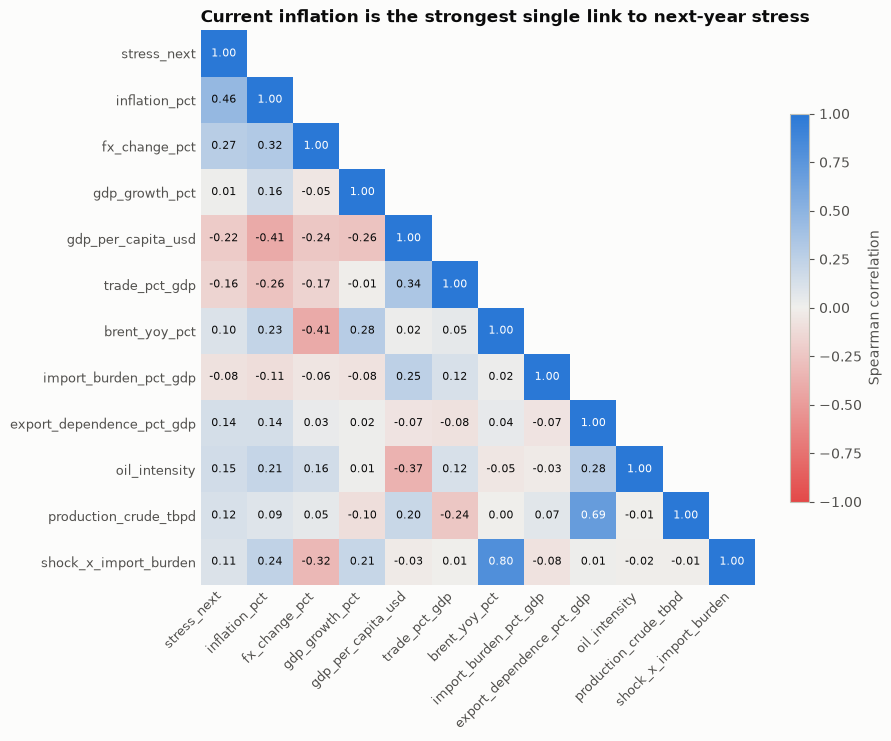

inflation_pct                0.46
fx_change_pct                0.27
gdp_per_capita_usd          -0.22
trade_pct_gdp               -0.16
oil_intensity                0.15
export_dependence_pct_gdp    0.14
production_crude_tbpd        0.12
shock_x_import_burden        0.11
brent_yoy_pct                0.10
import_burden_pct_gdp       -0.08
gdp_growth_pct               0.01
Name: stress_next, dtype: float64

In [10]:
HEATMAP_COLS = ['stress_next', 'inflation_pct', 'fx_change_pct', 'gdp_growth_pct', 'gdp_per_capita_usd',
                'trade_pct_gdp', 'brent_yoy_pct', 'import_burden_pct_gdp', 'export_dependence_pct_gdp',
                'oil_intensity', 'production_crude_tbpd', 'shock_x_import_burden']
corr = train[HEATMAP_COLS].corr(method='spearman')
corr.round(2).to_csv(TABLES / 'correlation_spearman_train.csv')

# Red = negative, grey = none, blue = positive. Upper triangle hidden because it repeats the lower.
diverging = LinearSegmentedColormap.from_list('red_blue', [RED, '#f0efec', BLUE])
hidden = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9, 7.2))
image = ax.imshow(np.ma.masked_where(hidden, corr.values), cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(HEATMAP_COLS)), HEATMAP_COLS, rotation=45, ha='right', fontsize=9)
ax.set_yticks(range(len(HEATMAP_COLS)), HEATMAP_COLS, fontsize=9)
for row in range(len(HEATMAP_COLS)):
    for col in range(row + 1):
        value = corr.values[row, col]
        ax.text(col, row, f'{value + 0.0:.2f}'.replace('-0.00', '0.00'), ha='center', va='center', fontsize=8,
                color='#ffffff' if abs(value) > 0.65 else INK)
ax.spines[['left', 'bottom']].set_visible(False)
ax.tick_params(length=0)
fig.colorbar(image, ax=ax, shrink=0.7, label='Spearman correlation')
ax.set_title('Current inflation is the strongest single link to next-year stress')
fig.savefig(FIGURES / 'correlation_heatmap_spearman.png', dpi=150, bbox_inches='tight')
plt.show()
corr['stress_next'].drop('stress_next').sort_values(key=abs, ascending=False).round(2)

**Takeaway:** the strongest links to next-year stress are current inflation (+0.46), exchange-rate
change (+0.27) and GDP per capita (-0.22). The oil columns are weaker: oil intensity +0.15, export
dependence +0.14, import burden -0.08. Two pairs carry overlapping information, which matters
for feature selection: `brent_yoy_pct` with `shock_x_import_burden` (+0.80), and
`production_crude_tbpd` with `export_dependence_pct_gdp` (+0.69).

## 10. Regional view

A compact table of how stress and crude import burden differ across regions.

In [11]:
regions = train.groupby('region').agg(countries=('iso3', 'nunique'), rows=('iso3', 'size'),
                                      stress_rate=('stress_next', 'mean'),
                                      median_import_burden=('import_burden_pct_gdp', 'median'))
regions = regions.sort_values('stress_rate', ascending=False).round(3)
regions.to_csv(TABLES / 'region_summary.csv')
regions

,countries,rows,stress_rate,median_import_burden
region,,,,
Sub-Saharan Africa,28,330,0.212,0.000
"Middle East, North Africa, Afghanistan & Pakistan",21,241,0.162,0.569
Europe & Central Asia,42,498,0.108,0.410
Latin America & Caribbean,24,273,0.103,0.000
South Asia,6,72,0.083,0.238
East Asia & Pacific,23,263,0.027,0.695
North America,2,24,0.000,0.717


## Summary

| Finding | What we do about it in Phase 2 |
|---|---|
| USD columns are heavily skewed; logs fix most of it | Test log features |
| Stress is rare (12.4%) and peaks at 36% in 2022 | Use F1 and ROC-AUC, class weights, threshold tuning |
| The main test never covers the start of a shock | Add the separate test on 2021 rows |
| Current inflation dominates; only 10% of test stress cases are new | Compare with the persistence rule; report new-onset results |
| Income confounds the oil relationship | Keep GDP per capita or income in the oil comparison |
| Crude-only data misses refined-fuel importers | Oil intensity may help; state this as a limitation |
| Some data-quality oddities (Myanmar FX, negative production) | Decide on capping or cleaning, and log the effect |